# Component 1: anomaly evaluation demonstration

Run all cells to reproduce the saved JKH and BIL evaluation without retraining. These are historical research results, not a new live analysis.

The stock research notebooks also include this section and use current training results if those cells have already been run.

## Anomaly detection: accuracy is not enough

An anomaly is an unusual movement, not automatically a good or bad investment.
We compare predicted flags with **research proxy labels**, not independently
confirmed real-world anomalies. False alarms and missed anomalies below are
relative to those proxy labels.

| Measure | Formula | Plain English |
|---|---|---|
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | Share of all checks classified correctly |
| Precision | $TP/(TP+FP)$ | Of the flags raised, how many matched a labelled anomaly? |
| Recall | $TP/(TP+FN)$ | Of the labelled anomalies, how many were detected? |
| F1 | $2TP/(2TP+FP+FN)$ | Balance between precision and recall |
| False alarms | $FP$ | Flagged, but the proxy label says normal |
| Missed anomalies | $FN$ | Proxy-labelled anomaly that was not flagged |

TP = correctly flagged anomaly; TN = correctly unflagged normal observation.
If a denominator is zero, the implementation reports zero for that metric.
The always-normal reference shows why high accuracy alone can hide missed rare
events. **Price forecast MAE, RMSE and MAPE are different measurements.**
In particular, `100 - MAPE` is not anomaly accuracy or a probability of success.

The cells below prefer current training results for this stock when available.
Otherwise they load the saved historical evaluation and show its dates explicitly.
They do not fetch today's prices or retrain a model by themselves.


In [1]:
from pathlib import Path
import sys
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Find the research package from either the repository or notebook directory.
_eval_candidates = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
                    for candidate in (parent, parent / "research" / "component1")]
EVAL_ROOT = next(candidate for candidate in _eval_candidates
                 if (candidate / "src" / "component1_research.py").is_file())
if str(EVAL_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(EVAL_ROOT / "src"))
from component1_research import compute_classification_metrics, compute_confusion_counts

def evaluation_binary(series):
    # Do not turn the string "False" into True by using astype(bool).
    encoded = series.astype(str).str.lower().map(
        {"true": 1, "false": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
    if encoded.isna().any():
        raise ValueError("Missing or invalid binary evaluation labels")
    return encoded.to_numpy(dtype=int)

def show_anomaly_evaluation(symbol, current_results=None):
    symbol = symbol.upper()
    if current_results is not None:
        test = current_results["test_results"].copy()
        comparison = current_results["anomaly_comparison"].copy()
        splits = current_results["anomaly_method_split_metrics"].copy()
        source = "Current in-kernel research run (not a saved historical result)"
        fingerprint = "See this notebook's training cells and configuration"
    else:
        folder = EVAL_ROOT / "artifacts" / "component1"
        test_path = folder / f"{symbol.lower()}_test_results.csv"
        test = pd.read_csv(test_path)
        comparison = pd.read_csv(folder / f"{symbol.lower()}_anomaly_comparison.csv")
        splits = pd.read_csv(folder / f"{symbol.lower()}_anomaly_method_split_metrics.csv")
        source = f"Saved historical evidence: {test_path.relative_to(EVAL_ROOT)}"
        fingerprint = hashlib.sha256(test_path.read_bytes()).hexdigest()

    actual = evaluation_binary(test["proxy_anomaly_label"])
    predicted = evaluation_binary(test["final_anomaly_detected"])
    metrics = compute_classification_metrics(actual, predicted)
    counts = compute_confusion_counts(actual, predicted)
    assert len(actual) > 0 and len(actual) == len(predicted)
    assert sum(counts[key] for key in ("tp", "tn", "fp", "fn")) == len(test)

    # Check the exported table against the row-level flags, not just its headline.
    stored = comparison.loc[comparison["method"] == "LSTM deviation method"]
    if len(stored) != 1:
        raise ValueError("Expected exactly one deviation-method comparison row")
    for key in ("accuracy", "precision", "recall", "f1_score"):
        assert np.isclose(float(stored.iloc[0][key]), metrics[key]), key
    for key in ("tp", "tn", "fp", "fn"):
        assert int(stored.iloc[0][key]) == counts[key], key

    dates = pd.to_datetime(test["date"], errors="raise")
    display(Markdown(f"### {symbol}: evaluation evidence"))
    display(pd.DataFrame([{
        "Source": source, "First test date": str(dates.min().date()),
        "Last test date": str(dates.max().date()), "Test observations": len(test),
        "Proxy-labelled anomalies": int(actual.sum()),
        "Proxy-labelled normal": int((actual == 0).sum()),
        "Anomaly prevalence (%)": round(100 * actual.mean(), 3),
        "Test CSV SHA-256 / run provenance": fingerprint,
    }]).T.rename(columns={0: "Value"}))

    normal_prediction = np.zeros_like(actual)
    reference = {"method": "Always normal (untrained reference)",
                 **compute_classification_metrics(actual, normal_prediction),
                 **compute_confusion_counts(actual, normal_prediction)}
    table = pd.concat([comparison, pd.DataFrame([reference])], ignore_index=True)
    def readable_table(frame):
        selected = [key for key in ("method", "split", "accuracy", "precision", "recall",
                    "f1_score", "fp", "fn", "tp", "tn", "support_positive") if key in frame]
        readable = frame[selected].copy()
        for key in ("accuracy", "precision", "recall"):
            readable[key] = (100 * readable[key]).round(2)
        readable["f1_score"] = readable["f1_score"].round(4)
        return readable.rename(columns={"method": "Method", "split": "Split",
            "accuracy": "Accuracy (%)", "precision": "Precision (%)", "recall": "Recall (%)",
            "f1_score": "F1 (0-1)", "fp": "False alarms (FP)", "fn": "Missed (FN)",
            "tp": "Detected (TP)", "tn": "Normal (TN)", "support_positive": "Labelled anomalies"})
    display(Markdown("#### Held-out test comparison"))
    display(readable_table(table))

    matrix = np.array([[counts["tn"], counts["fp"]], [counts["fn"], counts["tp"]]])
    fig, ax = plt.subplots(figsize=(6.5, 5.1), layout="constrained")
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(1, matrix.max()))
    descriptions = [["Correct normal (TN)", "False alarm (FP)"],
                    ["Missed anomaly (FN)", "Detected anomaly (TP)"]]
    for row in range(2):
        for col in range(2):
            ax.text(col, row, f"{matrix[row, col]}\n{descriptions[row][col]}",
                    ha="center", va="center", fontsize=10,
                    color="white" if matrix[row, col] > matrix.max() / 2 else "#122333")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normal", "Flagged anomaly"],
           yticklabels=["Normal", "Anomaly"], xlabel="Model prediction",
           ylabel="Research proxy label",
           title=f"{symbol}: deviation-method test confusion matrix\n"
                 f"{dates.min().date()} to {dates.max().date()}")
    figure_dir = EVAL_ROOT.parents[1] / "output" / "component1-notebook-evaluation"
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / f"{symbol.lower()}_anomaly_confusion.png", dpi=160)
    plt.show()
    plt.close(fig)

    display(Markdown(f"""#### What these results mean

The deviation method detected **{counts['tp']} of {counts['support_positive']}**
proxy-labelled anomalies (recall **{metrics['recall']:.1%}**). It raised
**{counts['fp']} false alarms** and missed **{counts['fn']}** labelled anomalies.
Of all flags raised, **{metrics['precision']:.1%}** matched the proxy labels.
Its F1 score was **{metrics['f1_score']:.4f}**.

The always-normal reference achieves **{reference['accuracy']:.1%} accuracy**
but detects **zero anomalies**. This is why accuracy alone is not sufficient.
These results do not prove real-world event detection, investment returns, or
accuracy on today's market. Small positive counts make precision and recall
sensitive to even one changed observation. Baselines can outperform the deviation
method; compare their F1 and false alarms rather than claiming a universal winner.
"""))
    display(Markdown("#### Split-level audit: training, validation and test"))
    display(readable_table(splits))
    display(Markdown("Training fits the models; validation supports threshold selection. "
                     "The held-out test checks performance and must not be used to tune the threshold. "
                     "Proxy labels are not independent expert-labelled ground truth."))
    return {"stock": symbol, **metrics, **counts}


### JKH: evaluation evidence

,Value
Source,Saved historical evidence: artifacts/component...
First test date,2023-08-16
Last test date,2026-05-07
Test observations,647
Proxy-labelled anomalies,9
Proxy-labelled normal,638
Anomaly prevalence (%),1.391
Test CSV SHA-256 / run provenance,9e625201892a5fe7c280be21a707fe639f13fd2f8a16ef...


#### Held-out test comparison

,Method,Accuracy (%),Precision (%),Recall (%),F1 (0-1),False alarms (FP),Missed (FN),Detected (TP),Normal (TN),Labelled anomalies
0,Z-score baseline,99.38,85.71,66.67,0.7500,1,3,6,637,9
1,Isolation Forest,96.91,26.09,66.67,0.3750,17,3,6,621,9
2,LSTM deviation method,95.21,21.05,88.89,0.3404,30,1,8,608,9
3,Always normal (untrained reference),98.61,0.00,0.00,0.0000,0,9,0,638,9


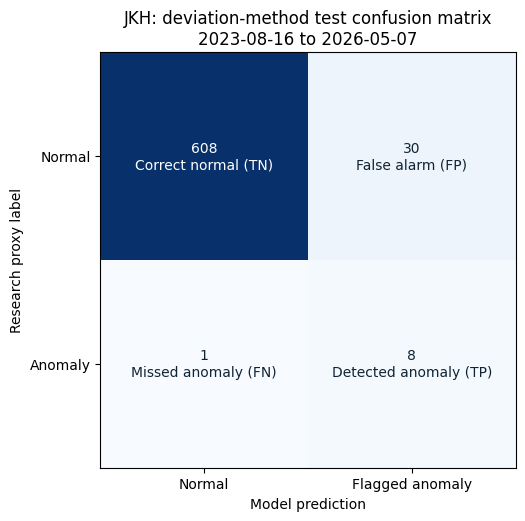

#### What these results mean

The deviation method detected **8 of 9**
proxy-labelled anomalies (recall **88.9%**). It raised
**30 false alarms** and missed **1** labelled anomalies.
Of all flags raised, **21.1%** matched the proxy labels.
Its F1 score was **0.3404**.

The always-normal reference achieves **98.6% accuracy**
but detects **zero anomalies**. This is why accuracy alone is not sufficient.
These results do not prove real-world event detection, investment returns, or
accuracy on today's market. Small positive counts make precision and recall
sensitive to even one changed observation. Baselines can outperform the deviation
method; compare their F1 and false alarms rather than claiming a universal winner.


#### Split-level audit: training, validation and test

,Method,Split,Accuracy (%),Precision (%),Recall (%),F1 (0-1),False alarms (FP),Missed (FN),Detected (TP),Normal (TN),Labelled anomalies
0,Z-score baseline,train,98.94,88.46,52.27,0.6571,3,21,23,2221,44
1,Z-score baseline,validation,78.33,84.21,19.28,0.3137,3,67,16,237,83
2,Z-score baseline,test,99.38,85.71,66.67,0.7500,1,3,6,637,9
3,Isolation Forest,train,95.24,21.93,56.82,0.3165,89,19,25,2135,44
4,Isolation Forest,validation,80.19,82.76,28.92,0.4286,5,59,24,235,83
5,Isolation Forest,test,96.91,26.09,66.67,0.3750,17,3,6,621,9
6,LSTM deviation method,train,93.12,10.56,34.09,0.1613,127,29,15,2097,44
7,LSTM deviation method,validation,78.64,79.17,22.89,0.3551,5,64,19,235,83
8,LSTM deviation method,test,95.21,21.05,88.89,0.3404,30,1,8,608,9


Training fits the models; validation supports threshold selection. The held-out test checks performance and must not be used to tune the threshold. Proxy labels are not independent expert-labelled ground truth.

In [2]:
anomaly_evaluation_jkh = show_anomaly_evaluation("JKH")

### BIL: evaluation evidence

,Value
Source,Saved historical evidence: artifacts/component...
First test date,2023-09-20
Last test date,2026-05-07
Test observations,629
Proxy-labelled anomalies,2
Proxy-labelled normal,627
Anomaly prevalence (%),0.318
Test CSV SHA-256 / run provenance,cfb327ad8fc202adc1e9fc421ebe7a7cb166d3753f305d...


#### Held-out test comparison

,Method,Accuracy (%),Precision (%),Recall (%),F1 (0-1),False alarms (FP),Missed (FN),Detected (TP),Normal (TN),Labelled anomalies
0,Z-score baseline,99.84,100.0,50.0,0.6667,0,1,1,627,2
1,Isolation Forest,99.84,100.0,50.0,0.6667,0,1,1,627,2
2,LSTM deviation method,99.36,25.0,50.0,0.3333,3,1,1,624,2
3,Always normal (untrained reference),99.68,0.0,0.0,0.0000,0,2,0,627,2


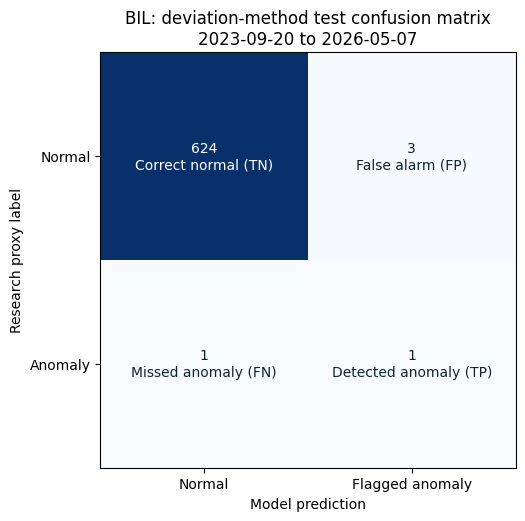

#### What these results mean

The deviation method detected **1 of 2**
proxy-labelled anomalies (recall **50.0%**). It raised
**3 false alarms** and missed **1** labelled anomalies.
Of all flags raised, **25.0%** matched the proxy labels.
Its F1 score was **0.3333**.

The always-normal reference achieves **99.7% accuracy**
but detects **zero anomalies**. This is why accuracy alone is not sufficient.
These results do not prove real-world event detection, investment returns, or
accuracy on today's market. Small positive counts make precision and recall
sensitive to even one changed observation. Baselines can outperform the deviation
method; compare their F1 and false alarms rather than claiming a universal winner.


#### Split-level audit: training, validation and test

,Method,Split,Accuracy (%),Precision (%),Recall (%),F1 (0-1),False alarms (FP),Missed (FN),Detected (TP),Normal (TN),Labelled anomalies
0,Z-score baseline,train,96.10,90.32,25.23,0.3944,3,83,28,2089,111
1,Z-score baseline,validation,88.22,100.00,7.50,0.1395,0,37,3,274,40
2,Z-score baseline,test,99.84,100.00,50.00,0.6667,0,1,1,627,2
3,Isolation Forest,train,93.92,39.64,39.64,0.3964,67,67,44,2025,111
4,Isolation Forest,validation,87.90,100.00,5.00,0.0952,0,38,2,274,40
5,Isolation Forest,test,99.84,100.00,50.00,0.6667,0,1,1,627,2
6,LSTM deviation method,train,62.19,3.72,26.13,0.0651,751,82,29,1341,111
7,LSTM deviation method,validation,87.90,57.14,20.00,0.2963,6,32,8,268,40
8,LSTM deviation method,test,99.36,25.00,50.00,0.3333,3,1,1,624,2


Training fits the models; validation supports threshold selection. The held-out test checks performance and must not be used to tune the threshold. Proxy labels are not independent expert-labelled ground truth.

In [3]:
anomaly_evaluation_bil = show_anomaly_evaluation("BIL")